In [1]:
   import causalml, dowhy
   from causalml.inference.meta import LRSRegressor, XGBTRegressor
   from dowhy import CausalModel
   from importlib.metadata import version
   print("causalml", version("causalml"), "| dowhy", version("dowhy"))

causalml 0.18.0 | dowhy 0.14


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
def load_acled_data(path):
    return pd.read_csv(path, parse_dates=["event_date"])

acled = load_acled_data("acled.csv")
acled.shape

In [5]:
print(acled["country"].value_counts())
print()
print(acled["event_type"].value_counts())

country
Ukraine              136165
Russia                33206
Mediterranean Sea       166
Pacific Ocean            24
Atlantic Ocean           15
Arctic Ocean              2
Name: count, dtype: int64

event_type
Explosions/Remote violence    112484
Battles                        44669
Strategic developments         10002
Protests                        1585
Violence against civilians       795
Riots                             43
Name: count, dtype: int64


In [6]:
print(acled["fatalities"].describe())
print("Share of events with 0 fatalities:", (acled["fatalities"] == 0).mean())

count    169578.000000
mean          0.911362
std           5.922991
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         594.000000
Name: fatalities, dtype: float64
Share of events with 0 fatalities: 0.8333097453679132


In [7]:
UKR_FRONT = ["Donetsk", "Kherson", "Kharkiv", "Zaporizhia", "Luhansk", "Sumy", "Dnipropetrovsk", "Chernihiv"]
RUS_FRONT = ["Kursk", "Belgorod", "Bryansk"]
FRONT = UKR_FRONT + RUS_FRONT

events = acled[acled["admin1"].isin(FRONT)].copy()
print("Events kept:", len(events), "of", len(acled))
print("Share of all fatalities kept:", events["fatalities"].sum() / acled["fatalities"].sum())

Events kept: 158738 of 169578
Share of all fatalities kept: 0.9890259920930202


In [ ]:
events["week"] = events["event_date"].dt.to_period("W-SUN").dt.start_time

In [9]:
print(events.columns.tolist())
print(events["sub_event_type"].value_counts())

['event_id_cnty', 'event_date', 'year', 'time_precision', 'disorder_type', 'event_type', 'sub_event_type', 'actor1', 'assoc_actor_1', 'inter1', 'actor2', 'assoc_actor_2', 'inter2', 'interaction', 'civilian_targeting', 'iso', 'region', 'country', 'admin1', 'admin2', 'admin3', 'location', 'latitude', 'longitude', 'geo_precision', 'source', 'source_scale', 'notes', 'fatalities', 'tags', 'timestamp', 'week']
sub_event_type
Air/drone strike                       57777
Shelling/artillery/missile attack      50124
Armed clash                            44074
Disrupted weapons use                   4742
Remote explosive/landmine/IED            694
Non-state actor overtakes territory      409
Looting/property destruction             195
Attack                                   176
Peaceful protest                         142
Government regains territory             119
Change to group/activity                  81
Other                                     67
Abduction/forced disappearance       

In this assignment im going to be looking at if air/drone strikes cause more fatalities per event than shelling/artillery/missile attacks, holding the front, time period and attacking force constant?

I want to look at this because the media has made drones to be this weapon that has revoulutionized war and made tanks and infantry tactics obsolete and drones are this new super deadly weapon, my hypothesis is that its not true and that artillery remains the deadlist form of weapon, thats not to say drones have changed some things but as the war continues countering drones have become more common.


In [14]:
treat_label = "Air/drone strike"
control_label = "Shelling/artillery/missile attack"

df_causal = events[events["sub_event_type"].isin([treat_label, control_label])].copy()

# Binary treatment: 1 = air/drone strike, 0 = shelling/artillery/missile
df_causal["treatment"] = (df_causal["sub_event_type"] == treat_label).astype(int)

print("Rows:", len(df_causal))
print(df_causal["treatment"].value_counts(normalize=True).round(3))

Rows: 107901
treatment
1    0.535
0    0.465
Name: proportion, dtype: float64


In [10]:
%pip install geopandas

  Using cached pyogrio-0.13.0-cp311-abi3-win_amd64.whl.metadata (6.0 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
Using cached pyogrio-0.13.0-cp311-abi3-win_amd64.whl (23.8 MB)
   ---------------------------------------- 0.0/6.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/6.7 MB ? eta -:--:--
   --- ------------------------------------ 0.5/6.7 MB 1.2 MB/s eta 0:00:06
   ---- ----------------------------------- 0.8/6.7 MB 1.3 MB/s eta 0:00:05
   ------ --------------------------------- 1.0/6.7 MB 1.3 MB/s eta 0:00:05
   ------- -------------------------------- 1.3/6.7 MB 1.3 MB/s eta 0:00:05
   --------- ------------------------------ 1.6/6.7 MB 1.2 MB/s eta 0:00:05
   ---------- ----------------------------- 1.8/6.7 MB 1.3 MB/s eta 0:00:04
   ------------ --------------------------- 2.1/6.7 MB 1.3 MB/s eta 0:00:04
   --------------- ------------------------ 2.6/6.7 MB 1.

In [15]:
import urllib.request

base = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/"
urllib.request.urlretrieve(base + "ne_50m_admin_0_countries.geojson", "countries.geojson")
urllib.request.urlretrieve(base + "ne_10m_admin_1_states_provinces.geojson", "regions.geojson")
print("Borders downloaded")

Borders downloaded


In [16]:
import geopandas as gpd

countries = gpd.read_file("countries.geojson")
regions = gpd.read_file("regions.geojson")
regions = regions[regions["admin"].isin(["Ukraine", "Russia"])]
print(len(countries), "countries |", len(regions), "Ukrainian and Russian regions")

242 countries | 111 Ukrainian and Russian regions


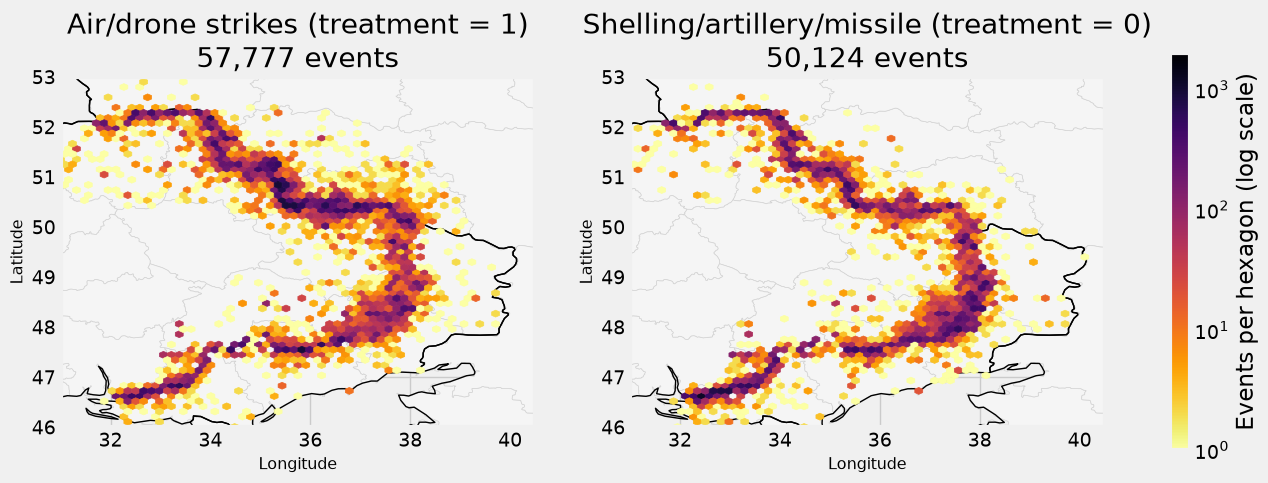

In [17]:
from matplotlib.colors import LogNorm

groups = {"Air/drone strikes (treatment = 1)": df_causal[df_causal["treatment"] == 1],
          "Shelling/artillery/missile (treatment = 0)": df_causal[df_causal["treatment"] == 0]}

fig, axs = plt.subplots(1, 2, figsize=(15, 7))
for ax, (title, sub) in zip(axs, groups.items()):
    regions.plot(ax=ax, color="whitesmoke", edgecolor="lightgrey", linewidth=0.5)
    countries.plot(ax=ax, color="none", edgecolor="black", linewidth=1)
    hb = ax.hexbin(sub["longitude"], sub["latitude"], gridsize=60, mincnt=1,
                   cmap="inferno_r", norm=LogNorm(vmin=1, vmax=2000),
                   extent=(31, 40.5, 46, 53))
    ax.set_xlim(31, 40.5)
    ax.set_ylim(46, 53)
    ax.set(title=f"{title}\n{len(sub):,} events", xlabel="Longitude", ylabel="Latitude")

fig.colorbar(hb, ax=axs, shrink=0.7, label="Events per hexagon (log scale)")
plt.show()

I am putting these maps once again just for a visual and a comparison where the weapons and how often they are used. Artillery and drone/air strikes are definetly the most widely used weapons, In reality testing to see which one causes more causualties may not be the best test to conduct as the weapons serve different purposes but due to the front lines having become stagnant they can be compared as they are being used to do the same job.

These two maps show where each type of remote strike took place. The left map shows air/drone strikes which is the treatment group, 57,777 events and the right map shows shelling/artillery/missile attacks which is the control group, 50,124 events. The area is divided into small hexagons, and each hexagon is coloured by how many events happened inside it, from pale yellow which is 1 event to black which is over 1,000 events.

There are a few hotspots near the front line with thousands of events while most areas have only a few. On a normal scale, the hotspots would hide everything else.

Both weapons follow the same front line from Kherson to Zaporizhzhia to Donetsk, to Kharkiv, and along the border with Belgorod, Kursk and Bryansk. The densest areas for both are around Donetsk and the Kharkiv Belgorod border because im using the same dataset with the incursion of kusk. One visible difference is that drone strikes are more spread out away from the front, with more scattered hexagons further behind the lines, while artillery stays closer to the front line itself.

This matters for the causal analysis because both weapons are used along the same fronts, there are comparable drone and artillery events in the same areas.

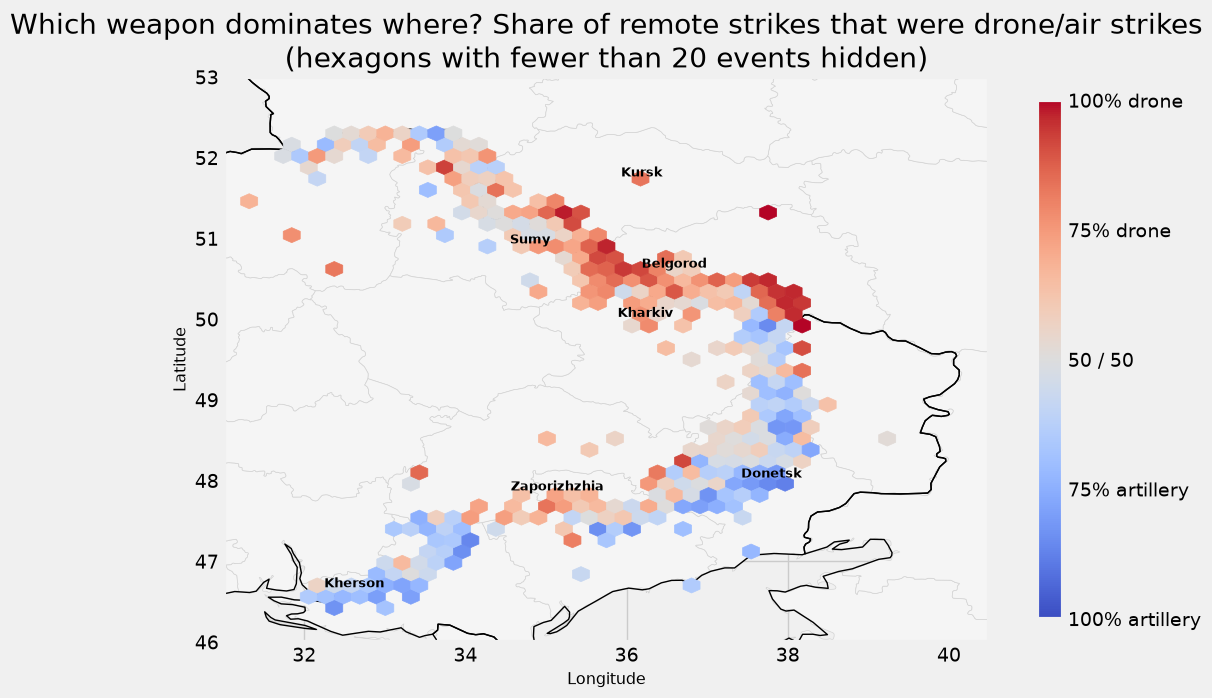

In [19]:
import numpy as np
import geopandas as gpd

countries = gpd.read_file("countries.geojson")
regions = gpd.read_file("regions.geojson")
regions = regions[regions["admin"].isin(["Ukraine", "Russia"])]

fig, ax = plt.subplots(figsize=(11, 8))
regions.plot(ax=ax, color="whitesmoke", edgecolor="lightgrey", linewidth=0.5)
countries.plot(ax=ax, color="none", edgecolor="black", linewidth=1)

# Colour each hexagon by the share of its strikes that were drones (mean of the 0/1 treatment)
hb = ax.hexbin(df_causal["longitude"], df_causal["latitude"], C=df_causal["treatment"],
               reduce_C_function=np.mean, gridsize=45, mincnt=20,
               cmap="coolwarm", vmin=0, vmax=1, extent=(31, 40.5, 46, 53))

cbar = fig.colorbar(hb, ax=ax, shrink=0.8)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
cbar.set_ticklabels(["100% artillery", "75% artillery", "50 / 50", "75% drone", "100% drone"])

for name, lon, lat in [("Kursk", 36.19, 51.73), ("Sumy", 34.80, 50.90), ("Belgorod", 36.59, 50.60),
                       ("Kharkiv", 36.23, 49.99), ("Donetsk", 37.80, 48.00), ("Zaporizhzhia", 35.14, 47.84),
                       ("Kherson", 32.62, 46.64)]:
    ax.text(lon, lat, name, fontsize=9, ha="center", va="bottom", fontweight="bold")

ax.set_xlim(31, 40.5)
ax.set_ylim(46, 53)
ax.set(title="Which weapon dominates where? Share of remote strikes that were drone/air strikes\n"
             "(hexagons with fewer than 20 events hidden)",
       xlabel="Longitude", ylabel="Latitude")
plt.show()

The first maps show that both weapons were used along the same front, but its difficult to read so I got claude to make another map thats easier to read. Red means mostly drone strikes, blue means mostly artillery, and white means a roughly even mix.

There is a clear north south split. Mostly due to the type of fighting and hpow industrial the areas are. Along the northern border, from Sumy through Belgorod to north of Kharkiv and near Kursk, strikes are mostly drone/air strikes, with several areas close to 100% drones. In the south and east, the Donetsk front and the Kherson area along the Dnipro river lean towards artillery. Artillery is used to stop the river crossings as its much more effective to target the area instead of precise drone dtrikes. Zaporizhzhia is mixed, and the Bryansk Chernihiv border area in the northwest is also a mix of both.

This shows that the choice of weapon depends partly on location. Location also affects how deadly fighting is, since some fronts are far more intense than others. That makes location a confounder, Donetsk is the deadliest front in the dataset and is mostly artillery, while the border regions are mostly drones, a simple comparison of average fatalities could make artillery look deadlier just because it is used more on the most intense front. it influences both the treatment and the outcome. If I compared all drone strikes with all artillery strikes without accounting for this, part of the difference would come from where each weapon is used rather than from the weapon itself. This is why the oblast is included as a control variable in the causal models.

In [20]:
summary = df_causal.groupby("treatment")["fatalities"].agg(
    events="size",
    mean_fatalities="mean",
    share_zero=lambda s: (s == 0).mean(),
    max_fatalities="max",
)
summary.index = ["Artillery (0)", "Drone/air (1)"]
summary.round(3)

,events,mean_fatalities,share_zero,max_fatalities
Artillery (0),50124,0.324,0.857,210
Drone/air (1),57777,0.167,0.917,100


Here we are just comparing drone/air strikes whith artillery with nothing held constant. Its the baseline for what I will use to compare with later, it doesnt look at where, when or by whom each weapon was used.

In [21]:
df_causal["actor1"].value_counts().head(10)

actor1
Military Forces of Russia (2000-)                                      40420
Military Forces of Russia (2000-) Air Force                            38904
Military Forces of Ukraine (2019-) Air Force                           18779
Military Forces of Ukraine (2019-)                                      9674
Police Forces of Ukraine (2019-) State Border Guard Service               42
Unidentified Military Forces                                              30
Military Forces of Ukraine (2019-) National Guard                          8
Military Forces of Ukraine (2019-) Main Directorate of Intelligence        8
Military Forces of Ukraine (2019-) Marines                                 8
Military Forces of Ukraine (2019-) Special Forces                          6
Name: count, dtype: int64

In [22]:
actor = df_causal["actor1"].str.lower()
df_causal["attacker"] = np.select(
    [actor.str.contains("of russia"), actor.str.contains("of ukraine")],
    ["Russia", "Ukraine"], default="Other")
print(df_causal["attacker"].value_counts())

attacker
Russia     79337
Ukraine    28532
Other         32
Name: count, dtype: int64


In [23]:
df_causal["air_force_unit"] = df_causal["actor1"].str.contains("Air Force")
pd.crosstab(df_causal["air_force_unit"], df_causal["treatment"],
            rownames=["Air Force unit"], colnames=["Treatment (1 = drone/air)"])

Treatment (1 = drone/air),0,1
Air Force unit,,
False,50114,104
True,10,57673


This table checks whether the “Air Force” label in actor1 lines up with the treatment. We can see that 57,673 of 57,777 drone/air strikes 99.8% are attributed to an Air Force unit, compared with only 10 of 50,124 artillery strikes. Its because ACLED attributes air/drone strikes to the Air Force by default. In reality this doesnt make sense because drones are operated by units within the army and not the air force but I assume it would be impossible to track every single unit as there are so many and new ones pop up everyday. I control only for the attacking side Russia vs. Ukraine and not the specific unit. Controlling for the unit would effectively mean controlling for the treatment itself, leaving no comparable drone and artillery strikes to compare.

In [24]:
df_model = df_causal[df_causal["attacker"] != "Other"].copy()
start = df_model["event_date"].min()
df_model["months_since_start"] = ((df_model["event_date"].dt.year - start.year) * 12
                                  + (df_model["event_date"].dt.month - start.month))
df_model["attacker_russia"] = (df_model["attacker"] == "Russia").astype(int)
oblast_dummies = pd.get_dummies(df_model["admin1"], prefix="oblast", drop_first=True, dtype=int)
df_model = pd.concat([df_model, oblast_dummies], axis=1)
control_cols = ["months_since_start", "attacker_russia"] + list(oblast_dummies.columns)
X = df_model[control_cols]                                                    
treatment = np.where(df_model["treatment"] == 1, "drone", "artillery")       
y = df_model["fatalities"].values 
print("X:", X.shape)
print(pd.Series(treatment).value_counts())
print(control_cols)

X: (107869, 12)
drone        57763
artillery    50106
Name: count, dtype: int64
['months_since_start', 'attacker_russia', 'oblast_Bryansk', 'oblast_Chernihiv', 'oblast_Dnipropetrovsk', 'oblast_Donetsk', 'oblast_Kharkiv', 'oblast_Kherson', 'oblast_Kursk', 'oblast_Luhansk', 'oblast_Sumy', 'oblast_Zaporizhia']


Here I set up the three inputs for the causal models, following the structure of the CausalML DragonNet example, the treatment, the target  and the control features.

 The controls are things that can affect both which weapon is used and how deadly a strike is

Oblast is imporant because the drone share map showed that weapon choice depends on the front, and some fronts are much deadlier than others.

Month is also important because as weve seen drones have become even more common. drone use grew over the course of the war, and fighting intensity changed over time.

Attacking side, both Russian and Ukrainian forces use different weapon mixes and strike different kinds of targets.

I deliberately left out civilian_targeting and exact latitude/longitude, because both partly depend on the weapon itself: who is hit is a result of the strike, and drones can reach further behind the front than artillery. Also it gets very tricky because sometimes drones do hit civilian vehicles that are travelling on roads so I I wanted to look at just military targets/personnel. 

 I also left out the unit , since it almost perfectly matches the treatment.

In [25]:
from causalml.inference.meta import LRSRegressor, XGBTRegressor


lrs = LRSRegressor(control_name="artillery")
ate_lrs, lb_lrs, ub_lrs = lrs.estimate_ate(X=X, treatment=treatment, y=y)
print(f"LRSRegressor ATE:  {ate_lrs[0]:.3f}  (95% CI {lb_lrs[0]:.3f} to {ub_lrs[0]:.3f})")


xgbt = XGBTRegressor(control_name="artillery", random_state=42)
ate_x, lb_x, ub_x = xgbt.estimate_ate(X=X, treatment=treatment, y=y)
print(f"XGBTRegressor ATE: {ate_x[0]:.3f}  (95% CI {lb_x[0]:.3f} to {ub_x[0]:.3f})")

LRSRegressor ATE:  -0.174  (95% CI -0.191 to -0.156)
XGBTRegressor ATE: -0.187  (95% CI -0.204 to -0.171)


Both CausalML learners estimate that an air/drone strike causes fewer deaths than an artillery strike, after holding the oblast, month and attacking side constant, −0.174 deaths per strike with LRSRegressor and −0.187 with XGBTRegressor. Relative to artillery’s average of 0.324 deaths per strike, this is roughly 55% fewer deaths. 

The controlled estimates are larger in size than the naive gap of −0.157. Drone strikes were used more in the places, periods or by the attacker where strikes tend to be deadlier, which made them look less different from artillery in the simple comparison. Once these factors are held constant, the difference between the weapons is larger. This makes sense though because the weapons are once again used for different purposes so the fact that the front lines have stagnated doesnt change their deadliness. Simply drones target vehicles and artillery targets infantry.


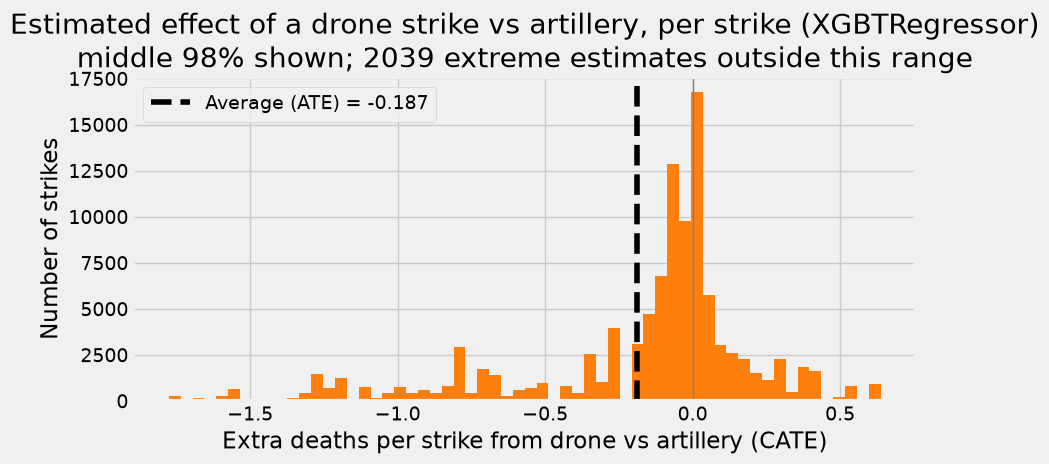

,strikes,drone_share,avg_effect,artillery_avg_deaths,effect_%_of_artillery
admin1,,,,,
Dnipropetrovsk,3358,0.678,-0.618,0.431,-143.433
Kharkiv,7820,0.472,-0.607,0.706,-86.078
Kursk,3967,0.802,-0.430,0.464,-92.583
Zaporizhia,9821,0.549,-0.417,0.385,-108.197
Donetsk,19051,0.353,-0.151,0.497,-30.371
Luhansk,1120,0.473,-0.146,0.632,-23.029
Kherson,16757,0.358,-0.116,0.284,-40.769
Sumy,20442,0.540,-0.074,0.099,-74.925
Belgorod,19102,0.810,-0.056,0.058,-96.618


In [27]:
import matplotlib.pyplot as plt


tau = xgbt.fit_predict(X=X, treatment=treatment, y=y)
df_model["cate"] = tau.ravel()

lo, hi = df_model["cate"].quantile([0.01, 0.99])
outside = ((df_model["cate"] < lo) | (df_model["cate"] > hi)).sum()

plt.figure(figsize=(9, 4))
plt.hist(df_model["cate"], bins=60, range=(lo, hi), color="tab:orange")
plt.axvline(df_model["cate"].mean(), color="black", ls="--", label=f"Average (ATE) = {df_model['cate'].mean():.3f}")
plt.axvline(0, color="grey", lw=1)
plt.title("Estimated effect of a drone strike vs artillery, per strike (XGBTRegressor)\n"
          f"middle 98% shown; {outside} extreme estimates outside this range")
plt.xlabel("Extra deaths per strike from drone vs artillery (CATE)")
plt.ylabel("Number of strikes")
plt.legend()
plt.show()


by_oblast = df_model.groupby("admin1").agg(
    strikes=("cate", "size"),
    drone_share=("treatment", "mean"),
    avg_effect=("cate", "mean"),
)
by_oblast["artillery_avg_deaths"] = df_model[df_model["treatment"] == 0].groupby("admin1")["fatalities"].mean()
by_oblast["effect_%_of_artillery"] = 100 * by_oblast["avg_effect"] / by_oblast["artillery_avg_deaths"]
by_oblast.sort_values("avg_effect").round(3)

This histogram shows the estimated drone vs artillery effect for each individual strike from the XGBoost T learner, zoomed in on the middle 98% of estimates. Most strikes have an estimated effect close to zero, which makes sense since 86–92% of strikes kill no one regardless of weapon. The average effect of −0.187 is driven by a long tail of strikes with large negative effects, meaning artillery is much deadlier than drones in specific situations rather than slightly deadlier everywhere. The jagged shape comes from the controls being categories, so strikes with the same combination receive the same estimate.

In [28]:
by_oblast["median_effect"] = df_model.groupby("admin1")["cate"].median()

naive_by_oblast = df_model.groupby(["admin1", "treatment"])["fatalities"].mean().unstack()
by_oblast["naive_gap_in_oblast"] = naive_by_oblast[1] - naive_by_oblast[0]

by_oblast[["strikes", "avg_effect", "median_effect", "naive_gap_in_oblast"]].sort_values("avg_effect").round(3)

,strikes,avg_effect,median_effect,naive_gap_in_oblast
admin1,,,,
Dnipropetrovsk,3358,-0.618,-0.327,-0.331
Kharkiv,7820,-0.607,-0.518,-0.369
Kursk,3967,-0.430,0.005,-0.070
Zaporizhia,9821,-0.417,-0.362,-0.108
Donetsk,19051,-0.151,-0.048,-0.019
Luhansk,1120,-0.146,0.022,-0.232
Kherson,16757,-0.116,-0.091,-0.146
Sumy,20442,-0.074,-0.038,-0.015
Belgorod,19102,-0.056,-0.043,-0.046


The table shows how the estimated effectiviness of drones are in every oblast. I used medians because some oblasts have extreme estimates. I also compared each oblast’s median effect and the simple drone vs artillery difference within that oblast.

For Kursk and Donetsk which are deadliest fronts the large averages come from a minority of extreme estimates and we see that the median effect is close to zero. Kursk is because  80% of strikes there were drone strikes, so the model of artillery strikes in Kursk is built on fewer than 800 events. Luhansk and Bryansk have too few strikes, and their measures disagree, to draw conclusions. Essentially the drone vs artillery difference is concentrated in specific fronts rather than spread evenly, and estimates for fronts with few strikes or very unbalanced weapon use should be treated with caution.

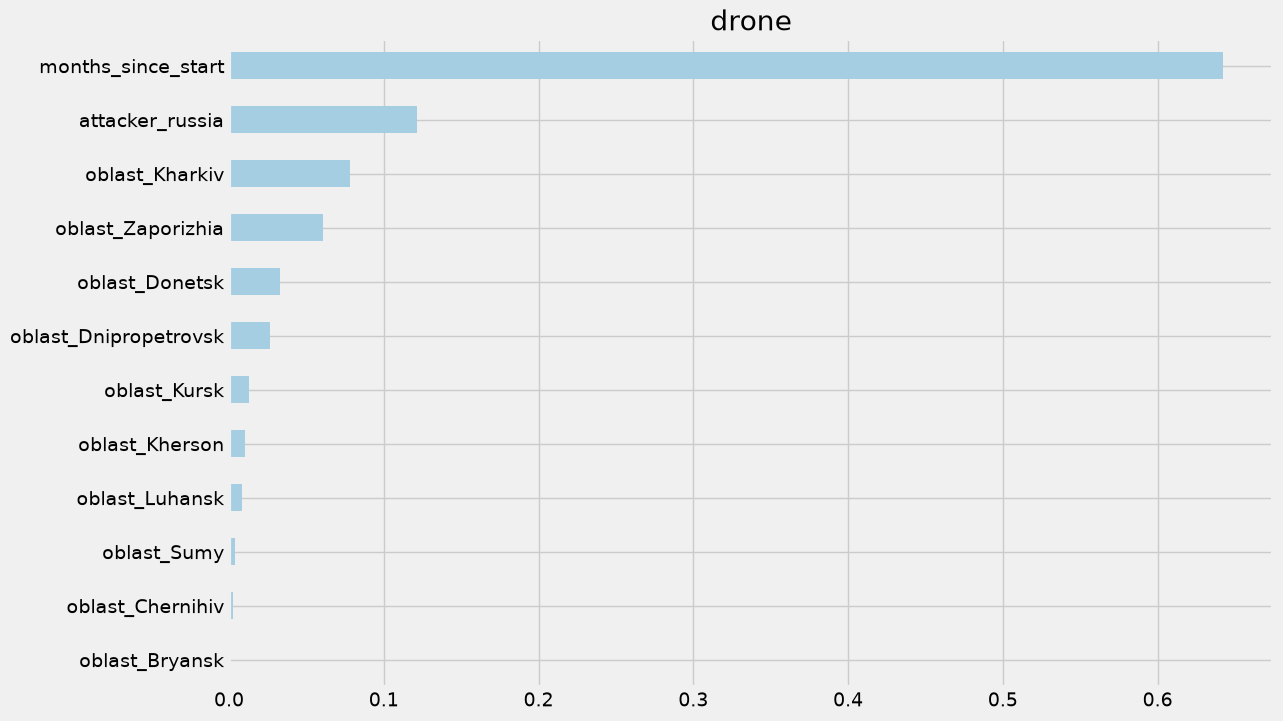

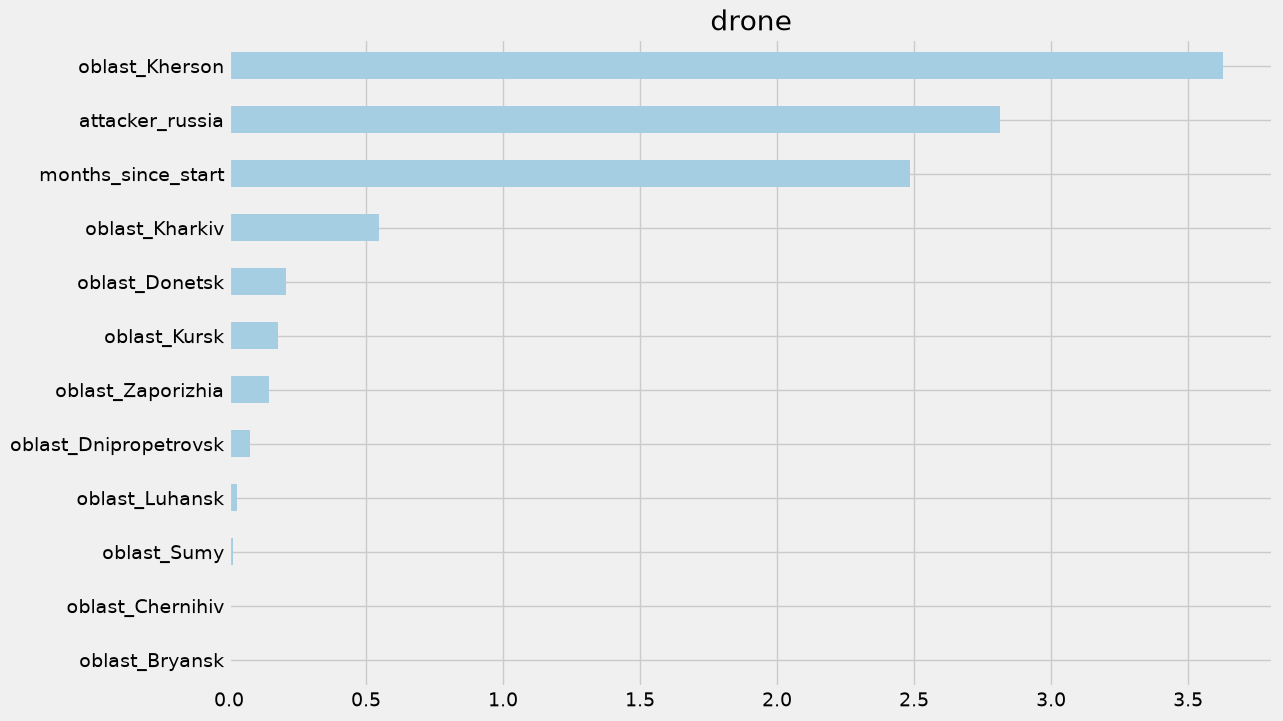

In [29]:
from lightgbm import LGBMRegressor


xgbt.plot_importance(X=X, tau=tau, method="auto", features=control_cols,
                     model_tau_feature=LGBMRegressor(importance_type="gain", verbose=-1))
plt.show()


xgbt.plot_importance(X=X, tau=tau, method="permutation", features=control_cols,
                     model_tau_feature=LGBMRegressor(importance_type="gain", verbose=-1),
                     random_state=42)
plt.show()

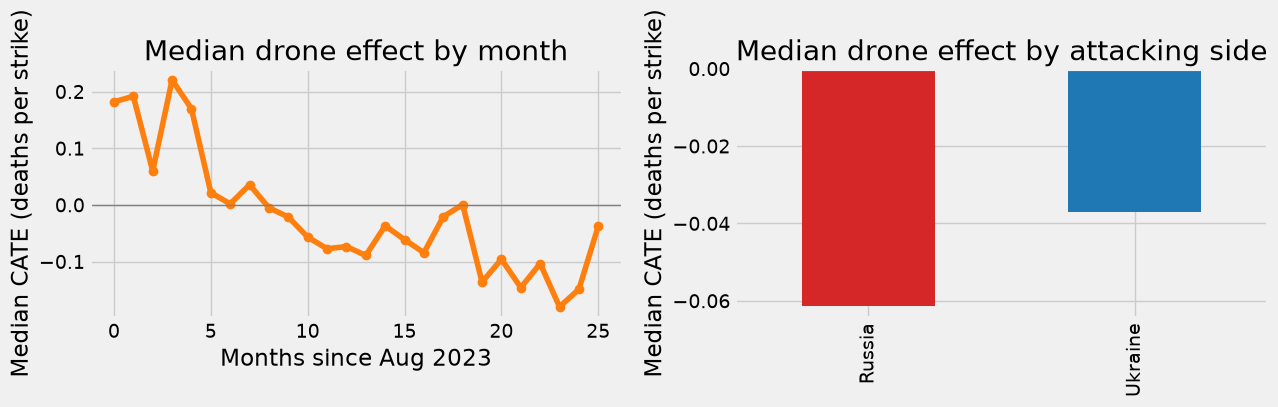

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

df_model.groupby("months_since_start")["cate"].median().plot(ax=axs[0], marker="o", color="tab:orange")
axs[0].axhline(0, color="grey", lw=1)
axs[0].set(title="Median drone effect by month", xlabel="Months since Aug 2023", ylabel="Median CATE (deaths per strike)")

df_model.groupby("attacker")["cate"].median().plot(kind="bar", ax=axs[1], color=["tab:red", "tab:blue"])
axs[1].axhline(0, color="grey", lw=1)
axs[1].set(title="Median drone effect by attacking side", xlabel="", ylabel="Median CATE (deaths per strike)")

plt.tight_layout()
plt.show()

These two plots show which features change how big the drone effect is from one strike to another. They don’t show what causes deaths in general. I used two different methods from the CausalML feature interpretation example, and both of them picked out the same three things as the most important: time, which side was attacking , and the location of the strike. So the gap between drones and artillery changed as the war went on, it was different for Russian and Ukrainian strikes, and it changed depending on the front. The quiet border regions like Sumy, Chernihiv and Bryansk barely show up in either plot, which makes sense since the drone effect there was close to zero anyway.

The two methods don’t agree on the order though. The first method puts time way ahead of everything else, but this method tends to favour features that have lots of different values. Time has about 26 values , while each oblast column is just a 0 or a 1, so time gets an unfair advantage. I wouldn’t say any one feature is the most important, just that time, the attacking side and the location all matter. These plots also only show how much a feature matters, not whether it makes the drone effect bigger or smaller.

In this section I estimate the same causal effect with Microsoft’s DoWhy library, following the “common causes” interface from the DoWhy simple example. DoWhy makes the causal assumptions explicit in four steps: model the assumptions, identify whether the effect can be estimated, estimate it, and refute stress test the estimate. I use the same treatment drone/air strike vs. artillery, outcome are fatalities per strike and common causes such as oblast, month, attacking side as in the CausalML section, so the results can be compared directly.

In [31]:
from dowhy import CausalModel


data_dowhy = df_model[["treatment", "fatalities"] + control_cols].copy()
data_dowhy["treatment"] = data_dowhy["treatment"].astype(bool)   # True = drone/air strike, False = artillery

model = CausalModel(
    data=data_dowhy,
    treatment="treatment",         
    outcome="fatalities",           
    common_causes=control_cols,     
)

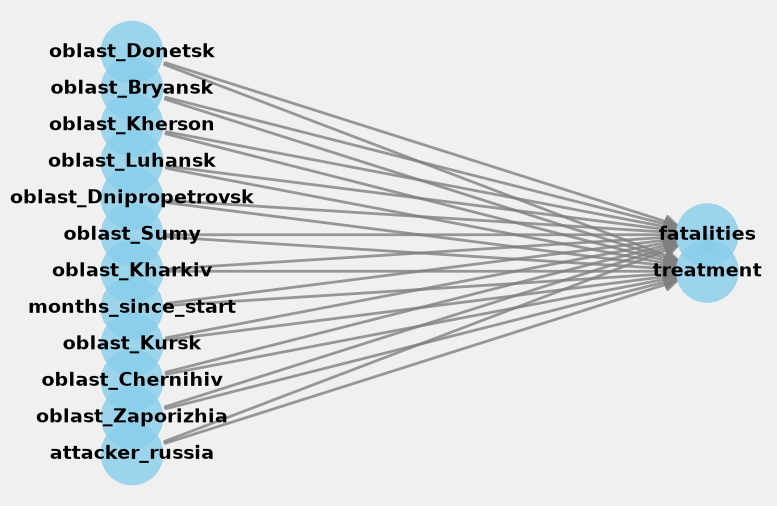

In [32]:
import matplotlib.pyplot as plt

model.view_model()
plt.show()

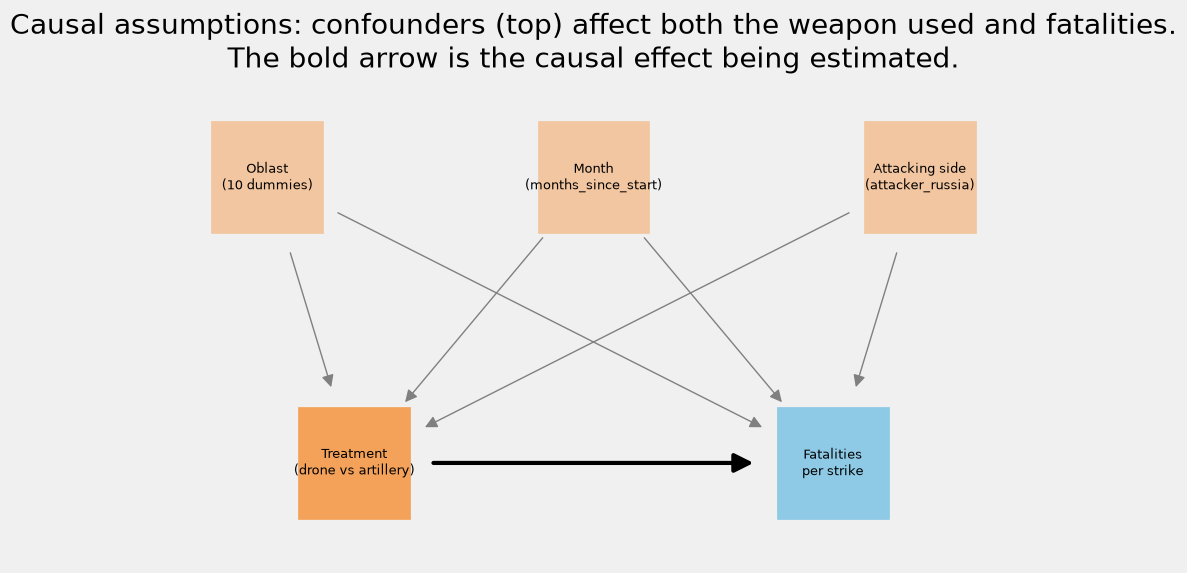

In [34]:
import networkx as nx

T, Y = "Treatment\n(drone vs artillery)", "Fatalities\nper strike"
confounders = ["Oblast\n(10 dummies)", "Month\n(months_since_start)", "Attacking side\n(attacker_russia)"]

G = nx.DiGraph()
for c in confounders:
    G.add_edge(c, T)
    G.add_edge(c, Y)
G.add_edge(T, Y)

# Confounders on top, treatment bottom-left, outcome bottom-right
pos = {confounders[0]: (0, 2), confounders[1]: (1.5, 2), confounders[2]: (3, 2), T: (0.4, 0), Y: (2.6, 0)}
colors = ["#f2c6a0" if n in confounders else ("#f4a259" if n == T else "#8ecae6") for n in G.nodes]

fig, ax = plt.subplots(figsize=(11, 6))
nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=6500, node_shape="s", ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=[e for e in G.edges if e[0] in confounders], edge_color="grey",
                       arrows=True, arrowsize=18, node_size=6500, node_shape="s", ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=[(T, Y)], edge_color="black", width=3,
                       arrows=True, arrowsize=28, node_size=6500, node_shape="s", ax=ax)
ax.set_title("Causal assumptions: confounders (top) affect both the weapon used and fatalities.\n"
             "The bold arrow is the causal effect being estimated.")
ax.set_xlim(-0.7, 3.7); ax.set_ylim(-0.7, 2.7); ax.axis("off")
plt.show()

The first graph is DoWhy’s view_model output. It shows the causal model built from the common causes: each of the 12 control columns has an arrow into both the treatment and fatalities.

That graph was kind of hard for me to understand, I got claude to make a simplified graph and this graph  shows the core assumption of the analysis. Oblast, month and attacking side each influence which weapon is used and how deadly a strike is. This makes them confounders. The bold arrow from treatment to fatalities is the causal effect I am estimating.

In [33]:
identified_estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                                                         ↪
────────────(E[fatalities|attacker_russia,oblast_Zaporizhia,oblast_Chernihiv,o ↪
d[treatment]                                                                   ↪

↪                                                                              ↪
↪ blast_Kursk,months_since_start,oblast_Kharkiv,oblast_Sumy,oblast_Dnipropetro ↪
↪                                                                              ↪

↪                                                                  
↪ vsk,oblast_Luhansk,oblast_Kherson,oblast_Bryansk,oblast_Donetsk])
↪                                                                  
Estimand assumption 1, Unconfoundedness: If U→{treatment} and U→fatalities then P(fatalities|treatment,attacker_russia,oblast_Zaporizhia,oblast_Chernihiv,oblast_Kursk,months_since_start,oblast_Kharki

In [36]:
from sklearn.linear_model import LogisticRegression


est_lr = model.estimate_effect(identified_estimand,
                               method_name="backdoor.linear_regression",
                               confidence_intervals=True)
print("Linear regression ATE:          ", round(est_lr.value, 3), "| 95% CI:", est_lr.get_confidence_intervals().round(3))

# Propensity model with more iterations so the logistic regression fully converges
ps_params = {"propensity_score_model": LogisticRegression(max_iter=1000)}


est_psw = model.estimate_effect(identified_estimand,
                                method_name="backdoor.propensity_score_weighting",
                                target_units="ate", method_params=ps_params)
print("Propensity score weighting ATE: ", round(est_psw.value, 3))


est_psm = model.estimate_effect(identified_estimand,
                                method_name="backdoor.propensity_score_matching",
                                target_units="ate", method_params=ps_params)
print("Propensity score matching ATE:  ", round(est_psm.value, 3))

Linear regression ATE:           -0.174 | 95% CI: [[-0.192 -0.155]]
Propensity score weighting ATE:  -0.193
Propensity score matching ATE:   -0.286


The propensity score methods work a bit differently from the regression. Essentially they first figure out how likely each strike was to be a drone strike based on the oblast, the month and which side carried it out, and then use that to make the drone and artillery groups more comparable. I had to increase the iterations of the logistic regression to 1,000 because with the default it stopped before it was done fitting.

Weighting came out at −0.193, which is very close to what XGBTRegressor gave. Matching came out higher at −0.286. Matching takes each strike and pairs it with the most similar strike from the other group, so it can be thrown off pretty easily with this data. Most strikes kill nobody and a few kill over 100, so if a few of the matches land on those mass casualty strikes the average moves a lot. It also has a harder time in places like Kursk and Belgorod where around 80% of strikes were drones, since there just aren’t many artillery strikes there to match with. That being said, it still shows drones being less deadly than artillery, it’s just the size of the effect I would be more careful with.

In [37]:

refute_rcc = model.refute_estimate(identified_estimand, est_lr,
                                   method_name="random_common_cause",
                                   num_simulations=20, random_seed=42)
print(refute_rcc)


refute_placebo = model.refute_estimate(identified_estimand, est_lr,
                                       method_name="placebo_treatment_refuter",
                                       placebo_type="permute",
                                       num_simulations=20, random_seed=42)
print(refute_placebo)


refute_subset = model.refute_estimate(identified_estimand, est_lr,
                                      method_name="data_subset_refuter",
                                      subset_fraction=0.8,
                                      num_simulations=20, random_seed=42)
print(refute_subset)

Refute: Add a random common cause
Estimated effect:-0.1736055633974616
New effect:-0.17361019239946157
p value:0.43772527169928466

Refute: Use a Placebo Treatment
Estimated effect:-0.1736055633974616
New effect:0.0009665801576056842
p value:0.45387091084062

Refute: Use a subset of data
Estimated effect:-0.1736055633974616
New effect:-0.17386144133837894
p value:0.4770470325221391



For the last DoWhy step I ran three refutation tests on the linear regression estimate of −0.174. Each test was repeated 20 times, and for all three a p value above 0.05 means the estimate passed.

The first test adds a made up confounder that’s just random noise. The estimate didn’t move at all, so adding a variable that has nothing to do with the outcome doesn’t change the result.

The second one is the placebo test, which randomly shuffles which strikes are labelled as drone strikes. When I did that, the effect dropped to basically zero. This is the one I find most convincing, because it shows the effect actually comes from the real weapon labels and isn’t something the method creates on its own.

The third test re runs the estimate on random 80% chunks of the data. It came out almost the same, so the result doesn’t depend on one particular group of strikes.

So the estimate passed all three. That being said, these tests can’t prove there isn’t a real confounder missing. The random common cause test only adds random noise, not something real like the type of target, which ACLED doesn’t record. The result holds up to DoWhy’s checks, but it’s still only causal if oblast, month and attacking side really are the main things affecting both the weapon used and the number of deaths.

In [38]:

df_model["kursk"] = (df_model["admin1"] == "Kursk").astype(int)


df_model["drone_strike"] = df_model["treatment"]


k_summary = df_model.groupby("kursk")["fatalities"].agg(
    strikes="size",
    mean_fatalities="mean",
    share_zero=lambda s: (s == 0).mean(),
)
k_summary.index = ["Other fronts (0)", "Kursk (1)"]
k_summary.round(3)

,strikes,mean_fatalities,share_zero
Other fronts (0),103902,0.233,0.894
Kursk (1),3967,0.408,0.758


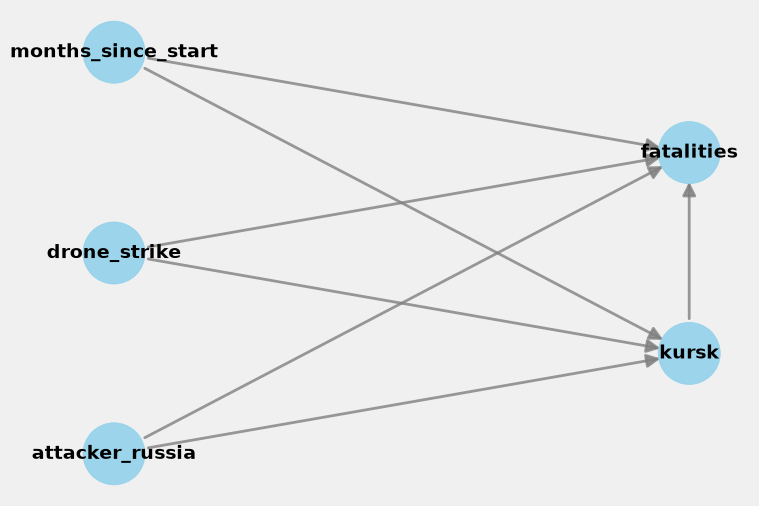

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
   d                                                                   
────────(E[fatalities|attacker_russia,drone_strike,months_since_start])
d[kursk]                                                               
Estimand assumption 1, Unconfoundedness: If U→{kursk} and U→fatalities then P(fatalities|kursk,attacker_russia,drone_strike,months_since_start,U) = P(fatalities|kursk,attacker_russia,drone_strike,months_since_start)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
   d                                                                   
────────(E[fatalities|attacker_russia,drone_strike,months_since_start])
d[kursk]                                                               
Estimand assumption 1, Unconfoundedne

In [39]:
kursk_causes = ["months_since_start", "attacker_russia", "drone_strike"]

data_kursk = df_model[["kursk", "fatalities"] + kursk_causes].copy()
data_kursk["kursk"] = data_kursk["kursk"].astype(bool)

model_k = CausalModel(
    data=data_kursk,
    treatment="kursk",
    outcome="fatalities",
    common_causes=kursk_causes,
)
model_k.view_model()
plt.show()

estimand_k = model_k.identify_effect(proceed_when_unidentifiable=True)
print(estimand_k)

In [40]:
est_k_lr = model_k.estimate_effect(estimand_k,
                                   method_name="backdoor.linear_regression",
                                   confidence_intervals=True)
print("Linear regression:          ", round(est_k_lr.value, 3), "| 95% CI:", est_k_lr.get_confidence_intervals().round(3))

est_k_psw = model_k.estimate_effect(estimand_k,
                                    method_name="backdoor.propensity_score_weighting",
                                    target_units="ate",
                                    method_params={"propensity_score_model": LogisticRegression(max_iter=1000)})
print("Propensity score weighting: ", round(est_k_psw.value, 3))

Linear regression:           0.249 | 95% CI: [[0.205 0.294]]
Propensity score weighting:  0.204


In [42]:
print(model_k.refute_estimate(estimand_k, est_k_lr, method_name="placebo_treatment_refuter",
                              placebo_type="permute", num_simulations=20, random_seed=42))
print(model_k.refute_estimate(estimand_k, est_k_lr, method_name="random_common_cause",
                              num_simulations=20, random_seed=42))

Refute: Use a Placebo Treatment
Estimated effect:0.24913454269559063
New effect:0.0037512803377403397
p value:0.42869277637826725

Refute: Add a random common cause
Estimated effect:0.24913454269559063
New effect:0.24912724197458047
p value:0.4553123368443399



Both refutation tests pass for the Kursk estimate. Randomly shuffling which strikes are labelled as Kursk reduces the effect from +0.249 to essentially zero and adding a random confounder leaves it unchanged. As in the main analysis, this shows the estimate is stable, but it cannot rule out real confounders missing from the model.

In [41]:

post = df_model[df_model["event_date"] >= "2024-08-06"]

data_post = post[["kursk", "fatalities"] + kursk_causes].copy()
data_post["kursk"] = data_post["kursk"].astype(bool)

model_post = CausalModel(data=data_post, treatment="kursk", outcome="fatalities", common_causes=kursk_causes)
estimand_post = model_post.identify_effect(proceed_when_unidentifiable=True)
est_post = model_post.estimate_effect(estimand_post,
                                      method_name="backdoor.linear_regression",
                                      confidence_intervals=True)
print("Strikes since 6 Aug 2024:", len(post))
print("Kursk effect (post-incursion):", round(est_post.value, 3), "| 95% CI:", est_post.get_confidence_intervals().round(3))

Strikes since 6 Aug 2024: 63190
Kursk effect (post-incursion): 0.383 | 95% CI: [[0.339 0.427]]


In [45]:
kursk_strikes = df_model[df_model["admin1"] == "Kursk"].copy()
kursk_strikes["period"] = np.where(kursk_strikes["event_date"] >= "2024-08-06",
                                   "Incursion (from 6 Aug 2024)", "Before incursion")
pd.crosstab(kursk_strikes["period"], kursk_strikes["attacker"], margins=True)

attacker,Russia,Ukraine,All
period,,,
Before incursion,0,1214,1214
Incursion (from 6 Aug 2024),2174,579,2753
All,2174,1793,3967


In [46]:

for side in ["Russia", "Ukraine"]:
    sub = post[post["attacker"] == side]
    d = sub[["kursk", "fatalities", "months_since_start", "drone_strike"]].copy()
    d["kursk"] = d["kursk"].astype(bool)
    m = CausalModel(data=d, treatment="kursk", outcome="fatalities",
                    common_causes=["months_since_start", "drone_strike"])
    e = m.estimate_effect(m.identify_effect(proceed_when_unidentifiable=True),
                          method_name="backdoor.linear_regression", confidence_intervals=True)
    print(f"{side}: {len(sub)} strikes ({(sub['kursk'] == 1).sum()} in Kursk) | "
          f"Kursk effect {e.value:.3f} | 95% CI {e.get_confidence_intervals().round(3)}")

Russia: 46614 strikes (2174 in Kursk) | Kursk effect 0.301 | 95% CI [[0.259 0.343]]
Ukraine: 16576 strikes (579 in Kursk) | Kursk effect 0.726 | 95% CI [[0.597 0.855]]


Just looking at the raw numbers, strikes in Kursk killed 0.408 people on average compared to 0.233 on the other fronts, so a gap of + 0.175. Kursk strikes were also less likely to kill nobody.

Once I held the month, the attacking side and the weapon type constant, DoWhy estimated that over the whole period a strike in Kursk caused 0.249 more deaths than a similar strike somewhere else. Propensity score weighting gave a similar number at +0.204. The gap actually got bigger after adding the controls, and this ties back to the main analysis. Around 80% of the strikes in Kursk were drone strikes, and drones kill fewer people per strike than artillery, so all those drone strikes were dragging Kursk’s average down. Once you compare drone strikes to drone strikes and artillery to artillery, Kursk stands out even more.

The problem with the full period estimate is that it’s mixing two completely different situations. Before 6 August 2024 Kursk was a quiet border region and every single strike there was Ukraine striking into Russia. During the incursion it flipped and most strikes were Russia hitting Ukrainian forces inside Kursk. Because of that I’m using the post incursion estimate as my main Kursk result. Looking only at strikes from 6 August 2024 onwards, a strike in Kursk caused 0.383 more deaths than a similar strike elsewhere. This lines up with what I found in Assignment 1, where weekly deaths in Kursk went from almost nothing to over 100 as soon as the incursion started.

There is one problem though which is you can’t really “assign” a location the way you could assign a weapon, so this isn’t the same as testing an intervention. It’s more a measure of how much deadlier the conditions in Kursk were for the same kind of strike. As for why, the data can’t tell us, but it could be down to how intense the fighting was during the incursion, or differences in how events in Kursk were reported.

Conclusion:

In my Hypothesis I asked whether air/drone strikes cause more fatalities per strike than shelling/artillery/missile attacks on the Russia Ukraine front, holding the oblast, month and attacking side constant. The data does not support this, across every method, drone/air strikes cause fewer deaths per strike than artillery. I think there are multiple reasons why, even though the fronts have become stagnant and the weapons are being used to somewhat achieve the same goal, there still is a concrete difference, drones target vehicles to disable them, at best a drone strike on a tank can cause a catastrophic ammunition cookoff killing 4 crew members and aristrikes usually target infracsture such as bridges. Artillery and missile attacks tend to attack infantry and trenchlines which will obviously cause more deaths than drone strikes. The dataset ended in 2025 when the front lines were more fluid.

Relative to artillery's average of 0.324 deaths per strike, the main estimates mean roughly 55% fewer deaths per drone strike. The two methods gave the same result DoWhy's linear regression reproduces CausalML's LRSRegressor exactly, and propensity score weighting is very close to the XGBoost T learner, even though these methods work in completely different ways.

Association vs. causation: The naive comparison understated the difference between the weapons. After controlling for confounders, the gap grew from −0.157 to about −0.18. Drone strikes were used more in the oblasts, months or by the attacker where strikes tend to be deadlier, which made them look more similar to artillery in the simple comparison.

The effect is not spread evenly. It is consistently negative on the Kharkiv, Zaporizhia, Dnipropetrovsk and Kherson fronts, and close to zero in the quiet border regions, where few strikes kill anyone. Feature importance showed that time, the attacking side and location all explain how the drone effect varies, although the two importance methods disagreed on the order.

For the second treatment I switched to looking at whether a strike happened in Kursk or not. During the incursion, strikes in Kursk caused 0.383 more deaths than similar strikes on other fronts. Over the whole period the number was lower at +0.249, but that’s because it mixes two very different periods. Before the incursion every strike in Kursk was Ukraine striking into Russia, and during the incursion 79% were Russian strikes. When I split it by which side was attacking, Kursk was deadlier for both Russian strikes and Ukrainian strikes, so it isn’t just one side driving the result. This also fits with the main analysis. Around 80% of the strikes in Kursk were drones, which are less deadly, so Kursk’s simple average made the fighting there look less deadly than it actually was. It also matches what I found in Assignment 1, where deaths in Kursk shot up as soon as the incursion started.

Limitations

The biggest limitation is that these results are only causal if oblast, month and attacking side really are the main confounders, and there could be something important I couldn’t control for. The main one I can think of is the type of target, which ACLED doesn’t record. Drones are often used on vehicles and equipment, while artillery is more often aimed at positions and groups of soldiers, which would naturally lead to more deaths. The problem is that the target partly depends on the weapon in the first place, so the result is really the effect of the weapon together with how it usually gets used, not the weapon on its own.

The data itself has some issues too. ACLED uses conservative estimates for fatalities, and reporting probably isn’t the same across every front, or between Russian and Ukrainian territory. On top of that, 86–92% of strikes didn’t kill anyone while a few killed over 100, so the averages end up being driven by a small number of very deadly strikes. This is part of why matching and the per-strike estimates were so noisy.

The XGBoost T-learner also gave some extreme estimates for individual strikes. Kursk is a good example of this: its big average drone effect came completely from outliers, and the median was basically zero. That’s because the artillery side of the model in Kursk only had fewer than 800 strikes to learn from.

The weapon labels are also ACLED’s classification, not something directly observed. Almost every drone/air strike is put down as an Air Force unit, so the treatment is really based on how ACLED codes the events.

Lastly, for the Kursk part, location isn’t something you can assign the way you could in an experiment. So that result shows how much deadlier the conditions in Kursk were for the same kind of strike, not the effect of an intervention. On top of that, before the incursion there were no Russian strikes in Kursk at all, so there was nothing to compare against for that period.